# Voice, Email & Chat Response Playbook

**Skills shown:** customer service across phone, email and chat, effective listening, SOP / workflow compliance, accurate case logging.

This notebook holds the playbook as structured data, so it can be read, searched and checked. It covers:

1. A five-stage response flow shared by all three channels: greet and verify, listen and clarify, troubleshoot step by step, resolve or escalate, confirm and close
2. Channel-specific scripts for each stage
3. Empathy phrases for common situations
4. Email etiquette guidelines
5. A case-logging template with a completeness check, so every interaction is recorded accurately

> All names, references and company details in square brackets are placeholders. The sample case records at the end are illustrative, not real customer data.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('charts', exist_ok=True)
pd.set_option('display.max_colwidth', 200)
pd.set_option('display.width', 220)

STAGES = [
    '1. Greet & verify',
    '2. Listen & clarify',
    '3. Troubleshoot step by step',
    '4. Resolve or escalate',
    '5. Confirm & close',
]
print(len(STAGES), 'stages in the response flow')

5 stages in the response flow


## 1. Channel scripts by stage

Each script follows the same flow, so the customer gets the same quality of service on every channel. Only the tone and format change (spoken, written, or short and instant).

In [2]:
SCRIPTS = {
    'Voice': [
        "Thank you for calling [Company], my name is [Name]. May I have your name and account or reference number so I can verify your details?",
        "Let me make sure I understand: you are saying [issue]. When did this start, and what have you already tried?",
        "Let's go through this together. First, could you [step 1]? Thank you. Now, please [step 2].",
        "I have fixed this for you. / I can't resolve this on this call, so I am passing it to [team] with all the details so you won't have to repeat yourself. You will hear back by [time].",
        "To confirm, we have [action] and your reference number is [ID]. Is there anything else I can help you with today? Thank you for calling.",
    ],
    'Email': [
        "Dear [Name], thank you for contacting [Company]. I have verified your account using the details you provided (ref: [ID]).",
        "I understand that [issue], and I am sorry for the inconvenience. To resolve this quickly, could you please confirm [missing information]?",
        "Please follow these steps: 1. [step 1]  2. [step 2]  3. [step 3]. If any step does not work, reply with a screenshot or the exact message you see.",
        "I have [action taken]. / I have escalated your case to [team], who will contact you within [SLA time]. Your case number is [ID].",
        "Please reply to this email if the issue continues. This case will close automatically in [x] days. Kind regards, [Name]",
    ],
    'Chat': [
        "Hi [Name], thanks for reaching out! I'm [Agent]. Could you share your account or order number so I can verify your details?",
        "Thanks! Just to confirm: [issue], correct? Did this start today or earlier?",
        "Let's try this: [step 1]. Let me know once that's done and I'll guide you through the next step.",
        "All sorted! / I'm escalating this to [team] now and have added your full details, so you won't need to repeat anything. Expect an update by [time].",
        "Is there anything else I can help with? Thanks for chatting with us, [Name]!",
    ],
}

scripts_df = pd.DataFrame(SCRIPTS, index=STAGES)
scripts_df

,Voice,Email,Chat
1. Greet & verify,"Thank you for calling [Company], my name is [Name]. May I have your name and account or reference number so I can verify your details?","Dear [Name], thank you for contacting [Company]. I have verified your account using the details you provided (ref: [ID]).","Hi [Name], thanks for reaching out! I'm [Agent]. Could you share your account or order number so I can verify your details?"
2. Listen & clarify,"Let me make sure I understand: you are saying [issue]. When did this start, and what have you already tried?","I understand that [issue], and I am sorry for the inconvenience. To resolve this quickly, could you please confirm [missing information]?","Thanks! Just to confirm: [issue], correct? Did this start today or earlier?"
3. Troubleshoot step by step,"Let's go through this together. First, could you [step 1]? Thank you. Now, please [step 2].","Please follow these steps: 1. [step 1] 2. [step 2] 3. [step 3]. If any step does not work, reply with a screenshot or the exact message you see.",Let's try this: [step 1]. Let me know once that's done and I'll guide you through the next step.
4. Resolve or escalate,"I have fixed this for you. / I can't resolve this on this call, so I am passing it to [team] with all the details so you won't have to repeat yourself. You will hear back by [time].","I have [action taken]. / I have escalated your case to [team], who will contact you within [SLA time]. Your case number is [ID].","All sorted! / I'm escalating this to [team] now and have added your full details, so you won't need to repeat anything. Expect an update by [time]."
5. Confirm & close,"To confirm, we have [action] and your reference number is [ID]. Is there anything else I can help you with today? Thank you for calling.","Please reply to this email if the issue continues. This case will close automatically in [x] days. Kind regards, [Name]","Is there anything else I can help with? Thanks for chatting with us, [Name]!"


## 2. Response flow diagram

Every contact follows the same path. If the issue cannot be resolved at first line (L1), it is handed over with full notes, and the customer is still told what happens next before the contact is closed.

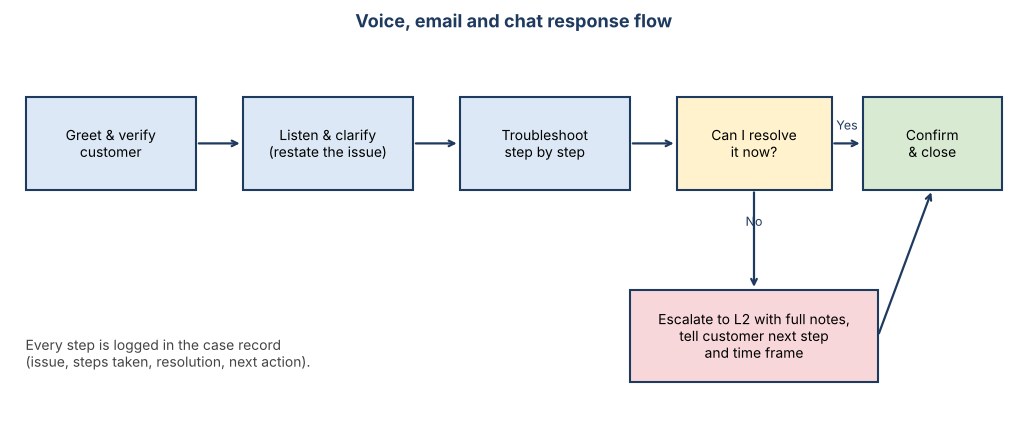

In [3]:
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.set_xlim(0, 13)
ax.set_ylim(0, 5.2)
ax.axis('off')

def box(x, y, w, h, text, fc):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec='#1F3A5F', lw=1.5, zorder=2))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=10, zorder=3, wrap=True)

def arrow(x1, y1, x2, y2, label=None):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color='#1F3A5F', lw=1.6), zorder=1)
    if label:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.18, label, ha='center', fontsize=9, color='#1F3A5F')

main = '#DCE8F5'
box(0.2, 3.2, 2.2, 1.2, 'Greet & verify\ncustomer', main)
box(3.0, 3.2, 2.2, 1.2, 'Listen & clarify\n(restate the issue)', main)
box(5.8, 3.2, 2.2, 1.2, 'Troubleshoot\nstep by step', main)
box(8.6, 3.2, 2.0, 1.2, 'Can I resolve\nit now?', '#FFF2CC')
box(11.0, 3.2, 1.8, 1.2, 'Confirm\n& close', '#D9EAD3')
box(8.0, 0.7, 3.2, 1.2, 'Escalate to L2 with full notes,\ntell customer next step\nand time frame', '#F8D7DA')

arrow(2.4, 3.8, 3.0, 3.8)
arrow(5.2, 3.8, 5.8, 3.8)
arrow(8.0, 3.8, 8.6, 3.8)
arrow(10.6, 3.8, 11.0, 3.8, 'Yes')
arrow(9.6, 3.2, 9.6, 1.9, 'No')
arrow(11.2, 1.3, 11.9, 3.2)
ax.text(0.2, 0.9, 'Every step is logged in the case record\n(issue, steps taken, resolution, next action).', fontsize=10, color='#444')
ax.set_title('Voice, email and chat response flow', fontsize=13, fontweight='bold', color='#1F3A5F')
plt.savefig('charts/response_flow.png', dpi=130, bbox_inches='tight')
plt.show()

## 3. Empathy phrases

Short phrases that show the customer they have been heard. They are used in stage 2 (listen and clarify) and stage 4 (resolve or escalate), and are matched to the situation, so they sound natural instead of scripted.

In [4]:
EMPATHY = {
    'Customer is frustrated': [
        "I understand how frustrating this must be, and I want to get it sorted for you.",
        "I'm sorry you've had to chase this. Let me take ownership of it now.",
        "Thank you for your patience while we look into this.",
    ],
    'Delay or waiting time': [
        "I apologise for the wait. I'll give you a clear update on where things stand.",
        "I know waiting is not ideal. Here is what is happening and when you can expect an update.",
        "Thank you for holding. I appreciate your time.",
    ],
    'Mistake on our side': [
        "You're right, and I'm sorry for the error on our side. Here is how I'll fix it.",
        "Thank you for pointing this out. I'll make sure it is corrected today.",
        "I apologise for the inconvenience this has caused.",
    ],
    'Customer is confused or non-technical': [
        "That's a fair question. Let me explain it in simple steps.",
        "No problem at all, we'll take this one step at a time.",
        "Let me check that I explained that clearly. Would you like me to go through it again?",
    ],
}

empathy_df = (pd.DataFrame([(k, p) for k, v in EMPATHY.items() for p in v],
                           columns=['Situation', 'Phrase']))
empathy_df

,Situation,Phrase
0,Customer is frustrated,"I understand how frustrating this must be, and I want to get it sorted for you."
1,Customer is frustrated,I'm sorry you've had to chase this. Let me take ownership of it now.
2,Customer is frustrated,Thank you for your patience while we look into this.
3,Delay or waiting time,I apologise for the wait. I'll give you a clear update on where things stand.
4,Delay or waiting time,I know waiting is not ideal. Here is what is happening and when you can expect an update.
5,Delay or waiting time,Thank you for holding. I appreciate your time.
6,Mistake on our side,"You're right, and I'm sorry for the error on our side. Here is how I'll fix it."
7,Mistake on our side,Thank you for pointing this out. I'll make sure it is corrected today.
8,Mistake on our side,I apologise for the inconvenience this has caused.
9,Customer is confused or non-technical,That's a fair question. Let me explain it in simple steps.


## 4. Email etiquette guidelines

In [5]:
ETIQUETTE = [
    'Use a clear subject line that includes the case or reference number.',
    'Greet the customer by name and thank them for contacting us.',
    'Acknowledge the issue in the first two sentences, in your own words.',
    'Keep paragraphs short. Use numbered steps for any instructions.',
    'Use plain language. Avoid internal jargon and abbreviations.',
    'State clearly what has been done, what happens next and by when.',
    'Reply within the SLA time, even if only to give a status update.',
    'Check names, numbers, attachments and spelling before sending.',
    'Close politely and invite the customer to reply if the issue continues.',
]
for i, rule in enumerate(ETIQUETTE, 1):
    print(f'{i}. {rule}')

1. Use a clear subject line that includes the case or reference number.
2. Greet the customer by name and thank them for contacting us.
3. Acknowledge the issue in the first two sentences, in your own words.
4. Keep paragraphs short. Use numbered steps for any instructions.
5. Use plain language. Avoid internal jargon and abbreviations.
6. State clearly what has been done, what happens next and by when.
7. Reply within the SLA time, even if only to give a status update.
8. Check names, numbers, attachments and spelling before sending.
9. Close politely and invite the customer to reply if the issue continues.


## 5. Case-logging template

Every interaction is recorded with the same fields, so that anyone picking up the case has the full story. The `log_case` function refuses an incomplete record, which is how the template enforces accuracy.

In [6]:
from datetime import datetime

REQUIRED_FIELDS = ['case_id', 'logged_at', 'channel', 'customer_ref', 'category', 'priority',
                   'issue', 'steps_taken', 'resolution', 'next_action', 'owner', 'status']

def log_case(**fields):
    missing = [f for f in REQUIRED_FIELDS if not str(fields.get(f, '')).strip()]
    if missing:
        raise ValueError(f'Incomplete case record, missing: {", ".join(missing)}')
    return {f: fields[f] for f in REQUIRED_FIELDS}

# Illustrative sample records (not real customer data)
sample_cases = [
    log_case(case_id='CS-0001', logged_at=datetime(2026, 11, 2, 10, 15), channel='Voice',
             customer_ref='ACC-1001', category='Billing', priority='P3',
             issue='Customer charged twice for one order',
             steps_taken='Verified identity; checked payment history; confirmed duplicate charge',
             resolution='Refund of duplicate charge raised',
             next_action='Confirm refund received after 3 working days', owner='Agent_01', status='Closed'),
    log_case(case_id='CS-0002', logged_at=datetime(2026, 11, 2, 11, 40), channel='Email',
             customer_ref='ACC-1002', category='Account access', priority='P2',
             issue='Cannot log in after password reset',
             steps_taken='Verified identity; guided customer through reset; issue persists',
             resolution='Not resolved at L1; escalated to L2 with screenshots',
             next_action='L2 to contact customer within 8 hours', owner='Agent_02', status='Escalated'),
    log_case(case_id='CS-0003', logged_at=datetime(2026, 11, 3, 9, 5), channel='Chat',
             customer_ref='ACC-1003', category='Order / Delivery', priority='P4',
             issue='Asked for the delivery date of an order',
             steps_taken='Verified order number; checked tracking status',
             resolution='Shared delivery date and tracking link',
             next_action='None', owner='Agent_01', status='Closed'),
]
log_df = pd.DataFrame(sample_cases)
log_df

,case_id,logged_at,channel,customer_ref,category,priority,issue,steps_taken,resolution,next_action,owner,status
0,CS-0001,2026-11-02 10:15:00,Voice,ACC-1001,Billing,P3,Customer charged twice for one order,Verified identity; checked payment history; confirmed duplicate charge,Refund of duplicate charge raised,Confirm refund received after 3 working days,Agent_01,Closed
1,CS-0002,2026-11-02 11:40:00,Email,ACC-1002,Account access,P2,Cannot log in after password reset,Verified identity; guided customer through reset; issue persists,Not resolved at L1; escalated to L2 with screenshots,L2 to contact customer within 8 hours,Agent_02,Escalated
2,CS-0003,2026-11-03 09:05:00,Chat,ACC-1003,Order / Delivery,P4,Asked for the delivery date of an order,Verified order number; checked tracking status,Shared delivery date and tracking link,None,Agent_01,Closed


In [7]:
# The template rejects an incomplete record
try:
    log_case(case_id='CS-0004', logged_at=datetime(2026, 11, 3, 14, 0), channel='Voice',
             customer_ref='ACC-1004', category='Billing', priority='P3',
             issue='Question about an invoice', steps_taken='', resolution='',
             next_action='', owner='Agent_03', status='Open')
except ValueError as e:
    print('Record rejected ->', e)

complete = log_df[REQUIRED_FIELDS].replace('', pd.NA).notna().all(axis=1).sum()
print(f'{complete} of {len(log_df)} sample records are complete')

Record rejected -> Incomplete case record, missing: steps_taken, resolution, next_action
3 of 3 sample records are complete
